In [1]:
!pip install -q osmnx

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import shapely
import osmnx as ox
from scipy.spatial import cKDTree
from pyproj import Transformer
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 100)

IN_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Component01/intermediate/stage4_map_matched")     # Stage 4 output (1 Hz + road evidence)
OSM_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Component01/data/reference/osm")                      # road network saved in Stage 4
MANUAL_REF = Path("/content/drive/MyDrive/Colab Notebooks/Component01/data/reference/manual_labels.csv")     # optional: hand-checked reference points
OUT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Component01/intermediate/stage5_labelled")
REPORT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Component01/outputs/stage5_labelling")
INVENTORY = Path("/content/drive/MyDrive/Colab Notebooks/Component01/outputs/stage1_inventory/inventory.csv")
OUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

trip_ids = sorted(p.stem for p in IN_DIR.glob("T*.csv"))
print(f"{len(trip_ids)} map-matched trips from Stage 4")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 3.3 MB/s eta 0:00:00
77 map-matched trips from Stage 4


In [2]:
CFG = {
    "crs_metric": "EPSG:32644",
    # --- surroundings evidence
    "density_radius_m": 500,          # junctions counted within 500 m (an area of 0.785 km2)
    "urban_junctions_km2": 50,        # >= 50 junctions/km2 -> dense street grid (urban)
    "suburban_junctions_km2": 15,     # 15-50 -> partly built-up fringe (suburban); < 15 -> open land
    "landuse_radius_m": 300,          # built-up share sampled within 300 m (supporting evidence only)
    # --- road evidence (OSM 'highway' classes)
    "expressway_classes": ["motorway", "motorway_link"],          # access-controlled expressway network
    "main_road_classes": ["trunk", "primary", "secondary"],       # A and B roads connecting towns
    # --- clean-up of short label changes
    "fill_unknown_gap_s": 10,         # short gaps without a road are filled if the same label is on both sides
    "min_run_s": 30,                  # a label must last >= 30 s; shorter runs are merged into a neighbour
    "confidence_margin": 0.3,         # density within +/-30 % of a threshold -> only 'medium' confidence
}
pd.Series(CFG, name="value").to_frame()

,value
crs_metric,EPSG:32644
density_radius_m,500
urban_junctions_km2,50
suburban_junctions_km2,15
landuse_radius_m,300
expressway_classes,"[motorway, motorway_link]"
main_road_classes,"[trunk, primary, secondary]"
fill_unknown_gap_s,10
min_run_s,30
confidence_margin,0.3


In [3]:
rules = pd.DataFrame([
    ("1", "Expressway", "matched road class is motorway or motorway_link",
     "the access-controlled expressway network (E01, E02 and their ramps / toll plazas)"),
    ("2", "Urban", f"not expressway AND junction density >= {CFG['urban_junctions_km2']} per km2",
     "a dense street grid means a built-up city area with frequent side roads"),
    ("3", "Suburban", f"not expressway AND {CFG['suburban_junctions_km2']} <= junction density < {CFG['urban_junctions_km2']}",
     "a moderate street grid: the fringe between city and open land"),
    ("4", "Intercity", f"not expressway AND density < {CFG['suburban_junctions_km2']} AND road is trunk / primary / secondary",
     "a main A / B road through open land, connecting towns"),
    ("5", "Rural", f"not expressway AND density < {CFG['suburban_junctions_km2']} AND minor road",
     "a minor road through open land (village roads)"),
    ("6", "Unknown", "no matched road (no GPS or unmatched in Stage 4)",
     "no location evidence, so no label is guessed"),
], columns=["rule", "label", "condition", "meaning"])
rules.to_csv(REPORT_DIR / "labelling_rules.csv", index=False)
rules

,rule,label,condition,meaning
0,1,Expressway,matched road class is motorway or motorway_link,"the access-controlled expressway network (E01, E02 and their ramps / toll plazas)"
1,2,Urban,not expressway AND junction density >= 50 per km2,a dense street grid means a built-up city area with frequent side roads
2,3,Suburban,not expressway AND 15 <= junction density < 50,a moderate street grid: the fringe between city and open land
3,4,Intercity,not expressway AND density < 15 AND road is trunk / primary / secondary,"a main A / B road through open land, connecting towns"
4,5,Rural,not expressway AND density < 15 AND minor road,a minor road through open land (village roads)
5,6,Unknown,no matched road (no GPS or unmatched in Stage 4),"no location evidence, so no label is guessed"


In [4]:
to_metric = Transformer.from_crs("EPSG:4326", CFG["crs_metric"], always_xy=True)

G = ox.load_graphml(OSM_DIR / "drive_network.graphml")
info = json.loads((OSM_DIR / "download_info.json").read_text())
nodes = ox.graph_to_gdfs(G, edges=False).to_crs(CFG["crs_metric"])
junction_tree = cKDTree(nodes.loc[nodes["street_count"] >= 3].geometry.get_coordinates().values)
circle_km2 = np.pi * (CFG["density_radius_m"] / 1000) ** 2
print(f"Road network from Stage 4 (downloaded {info['downloaded']}): {junction_tree.n:,} junctions")

LANDUSE_FILE = OSM_DIR / "landuse.geojson"
if not LANDUSE_FILE.exists():
    try:
        area = gpd.read_file(OSM_DIR / "study_area.geojson").geometry.iloc[0]
        lu = ox.features_from_polygon(area, tags={"landuse": ["residential", "commercial", "retail", "industrial"]})
        lu = lu[lu.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].reset_index()[["landuse", "geometry"]]
    except Exception as e:                                        # offline or nothing mapped
        print("Land-use download not available:", e)
        lu = gpd.GeoDataFrame({"landuse": []}, geometry=[], crs="EPSG:4326")
    lu.to_file(LANDUSE_FILE, driver="GeoJSON")
landuse = gpd.read_file(LANDUSE_FILE).to_crs(CFG["crs_metric"])
builtup = shapely.union_all(landuse.geometry.values) if len(landuse) else None
if builtup is not None:
    shapely.prepare(builtup)
print(f"Built-up land-use polygons: {len(landuse):,}" + ("" if len(landuse) else "  (built-up check skipped)"))

Road network from Stage 4 (downloaded 2026-10-21T12:52:37): 4,034 junctions
Built-up land-use polygons: 48


In [5]:
_offsets = np.array([(dx, dy) for dx in (-1, 0, 1) for dy in (-1, 0, 1)]) * CFG["landuse_radius_m"] * 0.67

def surroundings(lat, lon):
    """Junction density (per km2) and built-up share (0-1, or NaN) around each point."""
    x, y = to_metric.transform(lon, lat)
    xy = np.c_[x, y]
    density = junction_tree.query_ball_point(xy, CFG["density_radius_m"], return_length=True) / circle_km2
    share = np.full(len(xy), np.nan)
    if builtup is not None:
        px = xy[:, None, 0] + _offsets[None, :, 0]
        py = xy[:, None, 1] + _offsets[None, :, 1]
        share = shapely.contains_xy(builtup, px, py).mean(axis=1)    # 9 sample points around the location
    return density, share


def rule_label(road_class, density):
    """Apply rules 1-6 to every second."""
    rc = pd.Series(road_class).astype(object)
    has_road = rc.notna() & (rc.astype(str) != "None") & (rc.astype(str) != "nan")
    lab = np.full(len(rc), "Unknown", dtype=object)
    lab[has_road & rc.isin(CFG["expressway_classes"])] = "Expressway"
    other = has_road & ~rc.isin(CFG["expressway_classes"])
    lab[other & (density >= CFG["urban_junctions_km2"])] = "Urban"
    lab[other & (density < CFG["urban_junctions_km2"]) & (density >= CFG["suburban_junctions_km2"])] = "Suburban"
    low = other & (density < CFG["suburban_junctions_km2"])
    lab[low & rc.isin(CFG["main_road_classes"])] = "Intercity"
    lab[low & ~rc.isin(CFG["main_road_classes"])] = "Rural"
    return lab


def runs(labels):
    """Consecutive runs of the same label: list of [label, start, end_exclusive]."""
    out, start = [], 0
    for i in range(1, len(labels) + 1):
        if i == len(labels) or labels[i] != labels[start]:
            out.append([labels[start], start, i]); start = i
    return out


def smooth(labels):
    """1) fill short Unknown gaps between identical labels; 2) merge runs shorter than min_run_s."""
    lab = np.array(labels, dtype=object)
    r = runs(lab)
    for k in range(1, len(r) - 1):
        if r[k][0] == "Unknown" and r[k][2] - r[k][1] <= CFG["fill_unknown_gap_s"] and r[k - 1][0] == r[k + 1][0]:
            lab[r[k][1]:r[k][2]] = r[k - 1][0]
    while True:
        r = runs(lab)
        short = [k for k, (l, a, b) in enumerate(r) if b - a < CFG["min_run_s"] and len(r) > 1]
        if not short:
            break
        k = min(short, key=lambda k: r[k][2] - r[k][1])               # merge the shortest run first
        left = r[k - 1] if k > 0 else None
        right = r[k + 1] if k < len(r) - 1 else None
        nb = max([n for n in (left, right) if n], key=lambda n: n[2] - n[1])   # into the longer neighbour
        lab[r[k][1]:r[k][2]] = nb[0]
    return lab

In [6]:
def label_trip(tid):
    d = pd.read_csv(IN_DIR / f"{tid}.csv", parse_dates=["timestamp"])
    lat = d["snapped_lat"].fillna(d["gps_lat"]).values
    lon = d["snapped_lon"].fillna(d["gps_lon"]).values
    ok = ~np.isnan(lat)
    density = np.full(len(d), np.nan); share = np.full(len(d), np.nan)
    density[ok], share[ok] = surroundings(lat[ok], lon[ok])
    d["junction_density_km2"] = np.round(density, 1)
    d["builtup_share"] = np.round(share, 2)

    road = d["road_class"].where(d["match_flag"].isin(["matched", "low_confidence"]))
    d["env_rule_label"] = rule_label(road.values, np.nan_to_num(density, nan=-1))
    env = np.empty(len(d), dtype=object)
    for _, idx in d.groupby("segment_id").groups.items():              # never smooth across a logging gap
        env[np.asarray(idx)] = smooth(d.loc[idx, "env_rule_label"].values)
    d["environment"] = env

    # --- confidence: how strong and how consistent the evidence is
    conf = np.full(len(d), "high", dtype=object)
    lo_t, hi_t = CFG["suburban_junctions_km2"], CFG["urban_junctions_km2"]
    m = CFG["confidence_margin"]
    near_threshold = (np.abs(density - hi_t) < m * hi_t) | (np.abs(density - lo_t) < m * lo_t)
    non_exp = d["environment"].isin(["Urban", "Suburban", "Intercity", "Rural"]).values
    conf[non_exp & near_threshold] = "medium"
    if builtup is not None:                                             # land use disagrees with density
        disagree = ((d["environment"].isin(["Urban"]) & (share < 0.2)) |
                    (d["environment"].isin(["Intercity", "Rural"]) & (share > 0.6))).values
        conf[disagree] = "medium"
    uncertain_match = (d["match_flag"] == "low_confidence") & (d["dist_to_junction_m"] > 20)   # not just a junction
    conf[uncertain_match.values] = "medium"
    conf[(d["environment"] != d["env_rule_label"]).values] = "low"      # label set by smoothing / gap filling
    conf[(d["environment"] == "Unknown").values] = "none"
    d["env_confidence"] = conf

    d["env_evidence"] = ("road=" + road.fillna("none").astype(str)
                         + "; junctions=" + d["junction_density_km2"].fillna(-1).round(0).astype(int).astype(str) + "/km2"
                         + "; built-up=" + d["builtup_share"].map(lambda v: "n/a" if np.isnan(v) else f"{v:.2f}"))
    d["env_status"] = "rule-based (unverified)"
    return d

In [7]:
summ = []
for i, tid in enumerate(trip_ids, 1):
    d = label_trip(tid)
    d.to_csv(OUT_DIR / f"{tid}.csv", index=False)
    km = d["speed_kmh"].fillna(0) / 3600
    for env, g in d.groupby("environment"):
        summ.append({"trip_id": tid, "environment": env, "seconds": len(g), "km": km[g.index].sum(),
                     "changed_by_smoothing_s": int((g["env_rule_label"] != env).sum()),
                     "high_conf_s": int((g["env_confidence"] == "high").sum())})
    if i % 10 == 0 or i == len(trip_ids):
        print(f"{i}/{len(trip_ids)} trips labelled")

per_trip = pd.DataFrame(summ)
route = (pd.read_csv(INVENTORY).set_index("trip_id")["route_hint"] if INVENTORY.exists() else pd.Series(dtype=str))
per_trip["route"] = per_trip["trip_id"].map(route).fillna("all trips")
per_trip.to_csv(REPORT_DIR / "environment_per_trip.csv", index=False)

order = ["Urban", "Suburban", "Intercity", "Rural", "Expressway", "Unknown"]
table = per_trip.groupby("environment").agg(trips=("trip_id", "nunique"), hours=("seconds", lambda s: s.sum() / 3600),
                                            km=("km", "sum"), high_conf_s=("high_conf_s", "sum"), seconds=("seconds", "sum"))
table["high_confidence_%"] = 100 * table["high_conf_s"] / table["seconds"]
table["share_of_time_%"] = 100 * table["seconds"] / table["seconds"].sum()
table = table.reindex([e for e in order if e in table.index])[["trips", "hours", "km", "share_of_time_%", "high_confidence_%"]].round(1)
table.to_csv(REPORT_DIR / "environment_summary.csv")
table

/tmp/ipykernel_615/2159909880.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d = pd.read_csv(IN_DIR / f"{tid}.csv", parse_dates=["timestamp"])


10/77 trips labelled
20/77 trips labelled
30/77 trips labelled
40/77 trips labelled
50/77 trips labelled
60/77 trips labelled
70/77 trips labelled
77/77 trips labelled


,trips,hours,km,share_of_time_%,high_confidence_%
environment,,,,,
Urban,74,25.7,555.4,56.6,6.8
Suburban,72,2.1,45.8,4.5,24.6
Expressway,39,16.6,1248.7,36.6,93.4
Unknown,13,1.0,42.5,2.3,0.0


route,Route A,Route B
environment,,
Urban,91.1,4.8
Suburban,6.2,2.0
Expressway,0.0,91.6
Unknown,2.7,1.6


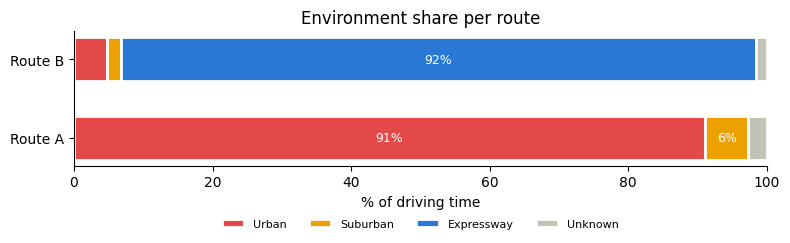

In [8]:
by_route = per_trip.pivot_table(index="environment", columns="route", values="seconds", aggfunc="sum").fillna(0)
by_route = (100 * by_route / by_route.sum()).round(1).reindex([e for e in order if e in by_route.index])
display(by_route)

colors = {"Urban": "#e34948", "Suburban": "#eda100", "Intercity": "#1baf7a", "Rural": "#6250d6",
          "Expressway": "#2a78d6", "Unknown": "#c3c2b7"}
fig, ax = plt.subplots(figsize=(8, 2.8))
left = np.zeros(by_route.shape[1])
for env in by_route.index:
    v = by_route.loc[env].values
    ax.barh(by_route.columns, v, left=left, color=colors[env], label=env, height=0.55, edgecolor="white", linewidth=2)
    for y, (l, val) in enumerate(zip(left, v)):
        if val > 6:
            ax.text(l + val / 2, y, f"{val:.0f}%", ha="center", va="center", fontsize=9, color="white")
    left += v
ax.set(xlim=(0, 100), xlabel="% of driving time", title="Environment share per route")
ax.legend(ncol=len(by_route.index), loc="upper center", bbox_to_anchor=(0.5, -0.32), frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORT_DIR / "environment_share.png", dpi=150)
plt.show()

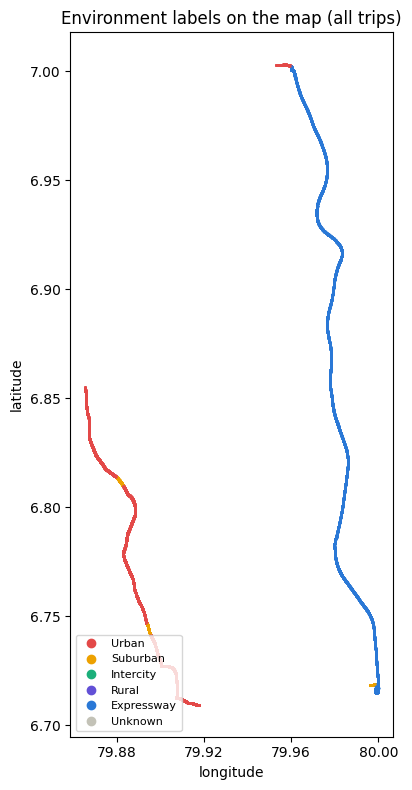

In [9]:
fig, ax = plt.subplots(figsize=(7, 8))
for tid in trip_ids:
    d = pd.read_csv(OUT_DIR / f"{tid}.csv", usecols=["snapped_lat", "snapped_lon", "environment"]).iloc[::5]
    for env, g in d.groupby("environment"):
        ax.plot(g["snapped_lon"], g["snapped_lat"], ".", ms=1.5, color=colors[env])
for env in order:
    ax.plot([], [], "o", color=colors[env], label=env)
ax.set_aspect("equal"); ax.xaxis.set_major_locator(plt.MaxNLocator(4))
ax.set(xlabel="longitude", ylabel="latitude", title="Environment labels on the map (all trips)")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig(REPORT_DIR / "environment_map.png", dpi=150)
plt.show()

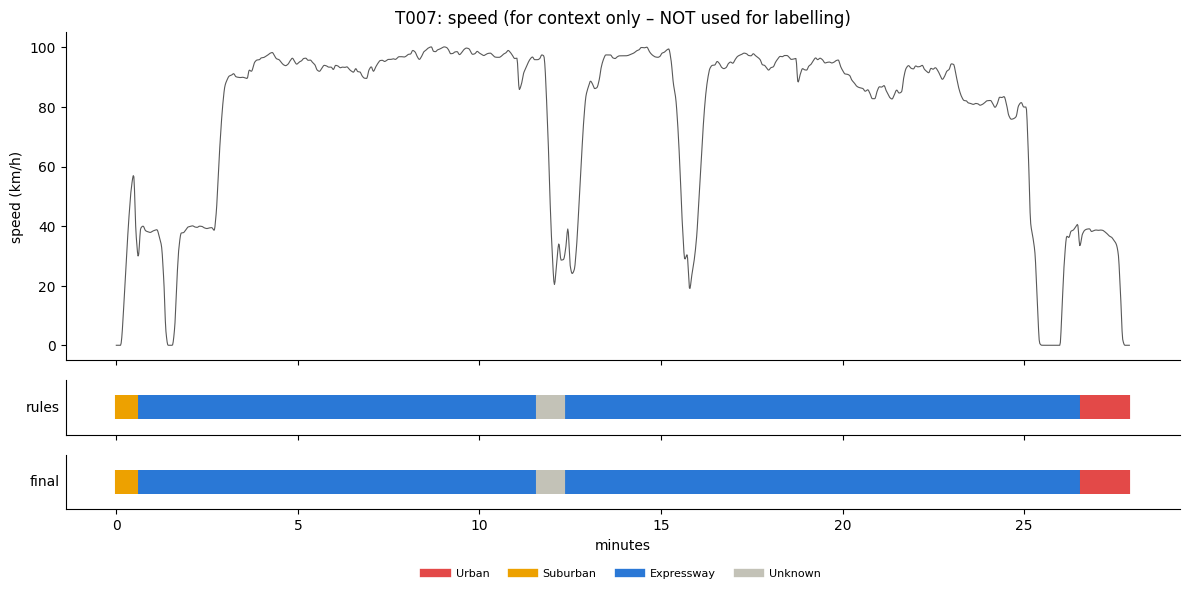

In [10]:
example = per_trip.groupby("trip_id")["environment"].nunique().idxmax()          # trip with the most environments
d = pd.read_csv(OUT_DIR / f"{example}.csv")
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 0.5, 0.5]})
axes[0].plot(d["t_s"] / 60, d["speed_kmh"], color="0.35", lw=0.8)
axes[0].set(ylabel="speed (km/h)", title=f"{example}: speed (for context only – NOT used for labelling)")
for ax, col, name in ((axes[1], "env_rule_label", "rules"), (axes[2], "environment", "final")):
    for env, g in d.groupby(col):
        ax.scatter(g["t_s"] / 60, np.zeros(len(g)), c=colors[env], marker="|", s=300, label=env)
    ax.set_yticks([]); ax.set_ylabel(name, rotation=0, ha="right", va="center")
axes[2].set_xlabel("minutes")
handles = [plt.Line2D([], [], color=colors[e], lw=6) for e in order if e in set(d["environment"]) | set(d["env_rule_label"])]
axes[2].legend(handles, [e for e in order if e in set(d["environment"]) | set(d["env_rule_label"])],
               ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.9), frameon=False, fontsize=8)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORT_DIR / "environment_timeline_example.png", dpi=150)
plt.show()

In [11]:
rows = []
all_d = pd.concat([pd.read_csv(OUT_DIR / f"{t}.csv", usecols=["road_class", "match_flag", "junction_density_km2"])
                   for t in trip_ids], ignore_index=True)
road = all_d["road_class"].where(all_d["match_flag"].isin(["matched", "low_confidence"]))
for factor in (0.75, 1.0, 1.25):
    saved = CFG["urban_junctions_km2"], CFG["suburban_junctions_km2"]
    CFG["urban_junctions_km2"], CFG["suburban_junctions_km2"] = saved[0] * factor, saved[1] * factor
    lab = pd.Series(rule_label(road.values, all_d["junction_density_km2"].fillna(-1).values))
    CFG["urban_junctions_km2"], CFG["suburban_junctions_km2"] = saved
    share = lab.value_counts(normalize=True).mul(100).round(1)
    rows.append(share.rename(f"thresholds x{factor} ({saved[0] * factor:.0f} / {saved[1] * factor:.0f} per km2)"))
sensitivity = pd.concat(rows, axis=1).fillna(0).reindex([e for e in order if e in pd.concat(rows, axis=1).index])
sensitivity.to_csv(REPORT_DIR / "threshold_sensitivity.csv")
print("Share of labelled time (%) when both density thresholds are changed by -25 % / 0 / +25 %:")
sensitivity

Share of labelled time (%) when both density thresholds are changed by -25 % / 0 / +25 %:


,thresholds x0.75 (38 / 11 per km2),thresholds x1.0 (50 / 15 per km2),thresholds x1.25 (62 / 19 per km2)
Urban,59.5,56.7,50.6
Suburban,1.9,4.7,10.8
Expressway,36.2,36.2,36.2
Unknown,2.3,2.3,2.3


In [12]:
checks = {}
for tid in trip_ids:
    d = pd.read_csv(OUT_DIR / f"{tid}.csv")
    s4 = pd.read_csv(IN_DIR / f"{tid}.csv", usecols=["timestamp"])
    checks.setdefault("same rows and timestamps as Stage 4", []).append(
        len(d) == len(s4) and (d["timestamp"].values == s4["timestamp"].values).all())
    checks.setdefault("every second has a label and a confidence", []).append(
        bool(d["environment"].notna().all() and d["env_confidence"].notna().all()))
    checks.setdefault("labels only from the allowed set", []).append(bool(d["environment"].isin(order).all()))
    raw_exp = d["env_rule_label"] == "Expressway"
    checks.setdefault("rule label 'Expressway' only on motorway / ramp", []).append(
        bool(d.loc[raw_exp, "road_class"].isin(CFG["expressway_classes"]).all()))
    lens = [b - a for seg, g in d.groupby("segment_id") for _, a, b in runs(g["environment"].values)]
    seg_len = d.groupby("segment_id").size()
    checks.setdefault(f"no label run shorter than {CFG['min_run_s']} s", []).append(
        bool(min(lens) >= CFG["min_run_s"] or (seg_len < CFG["min_run_s"]).any()))
    checks.setdefault("evidence recorded for every second", []).append(bool(d["env_evidence"].notna().all()))

verification = pd.DataFrame({k: [f"{sum(v)}/{len(v)}", "PASS" if all(v) else "CHECK"] for k, v in checks.items()},
                            index=["trips passing", "result"]).T
verification

,trips passing,result
same rows and timestamps as Stage 4,77/77,PASS
every second has a label and a confidence,77/77,PASS
labels only from the allowed set,77/77,PASS
rule label 'Expressway' only on motorway / ramp,77/77,PASS
no label run shorter than 30 s,77/77,PASS
evidence recorded for every second,77/77,PASS


In [13]:
print("STAGE 5 – ENVIRONMENT LABELLING: KEY RESULTS")
print("-" * 60)
print("Evidence used: matched road class (Stage 4) + junction density within 500 m"
      + (" + built-up land use (support)" if builtup is not None else "") + ". Speed is NOT used.")
for env, r in table.iterrows():
    print(f"  {env:10s}: {r['hours']:5.1f} h, {r['km']:7.1f} km, {r['share_of_time_%']:5.1f}% of time, "
          f"{r['high_confidence_%']:5.1f}% high confidence")
print(f"Seconds changed by smoothing: {per_trip['changed_by_smoothing_s'].sum():,} "
      f"({100 * per_trip['changed_by_smoothing_s'].sum() / per_trip['seconds'].sum():.1f} %)")
print("Status: rule-based (unverified)" + (" + manual reference check" if MANUAL_REF.exists() else ""))
print("Verification:", "all checks PASS" if (verification["result"] == "PASS").all() else "see table above")

STAGE 5 – ENVIRONMENT LABELLING: KEY RESULTS
------------------------------------------------------------
Evidence used: matched road class (Stage 4) + junction density within 500 m + built-up land use (support). Speed is NOT used.
  Urban     :  25.7 h,   555.4 km,  56.6% of time,   6.8% high confidence
  Suburban  :   2.1 h,    45.8 km,   4.5% of time,  24.6% high confidence
  Expressway:  16.6 h,  1248.7 km,  36.6% of time,  93.4% high confidence
  Unknown   :   1.0 h,    42.5 km,   2.3% of time,   0.0% high confidence
Seconds changed by smoothing: 942 (0.6 %)
Status: rule-based (unverified)
Verification: all checks PASS


In [14]:
# How many road types does the Stage 4 network contain?
edges = ox.graph_to_gdfs(G, nodes=False)
print(edges["highway"].astype(str).value_counts().head(15))
print(f"Nodes: {len(nodes):,}   Edges: {len(edges):,}")

# Split trips by behaviour: expressway trips have Expressway seconds
diag = []
for tid in trip_ids:
    d = pd.read_csv(OUT_DIR / f"{tid}.csv", usecols=["match_flag", "road_class", "environment"])
    kind = "expressway trip" if (d["environment"] == "Expressway").any() else "urban trip"
    diag.append(d.assign(trip_kind=kind))
diag = pd.concat(diag)
display(pd.crosstab(diag["trip_kind"], diag["match_flag"].fillna("NaN"), normalize="index").mul(100).round(1))
display(pd.crosstab(diag["trip_kind"], diag["environment"], normalize="index").mul(100).round(1))

highway
residential       10024
living_street      1448
tertiary           1100
primary            1073
trunk               533
unclassified        193
secondary            77
motorway_link        42
primary_link         38
motorway             27
trunk_link           26
tertiary_link         2
secondary_link        2
Name: count, dtype: int64
Nodes: 6,710   Edges: 14,585


match_flag,low_confidence,matched,no_gps
trip_kind,,,
expressway trip,8.3,90.1,1.7
urban trip,18.1,79.1,2.8


environment,Expressway,Suburban,Unknown,Urban
trip_kind,,,,
expressway trip,91.6,2.0,1.6,4.8
urban trip,0.0,6.2,2.7,91.1
